Loading models... (This may take a moment on the first run)

--- QUERY ---
'How to catch a computer virus?'

--- EXPERIMENT 1: Bi-Encoder (Dense Passage Retrieval) ---
Cosine Similarity Scores (Higher is better):
[0.4852] Medical (Distractor): To catch a virus early, doctors recommend regular ...
[0.6927] Tech (Target 1): Downloading suspicious executable files is a commo...
[0.4731] Tech (Target 2): Protect your PC from malware, trojans, and phishin...
[0.3013] Flu (Distractor): The flu virus spreads rapidly during the winter mo...
[0.2411] Finance (Distractor): Apple stock caught a cold today as market shares p...

--- EXPERIMENT 2: Cross-Encoder (Neural Reranker) ---
Cross-Encoder Relevance Scores (Higher is better, scale varies):
[0.6090] Medical (Distractor): To catch a virus early, doctors recommend regular ...
[9.3543] Tech (Target 1): Downloading suspicious executable files is a commo...
[-3.3428] Tech (Target 2): Protect your PC from malware, trojans, and phishin...
[-10.9637]

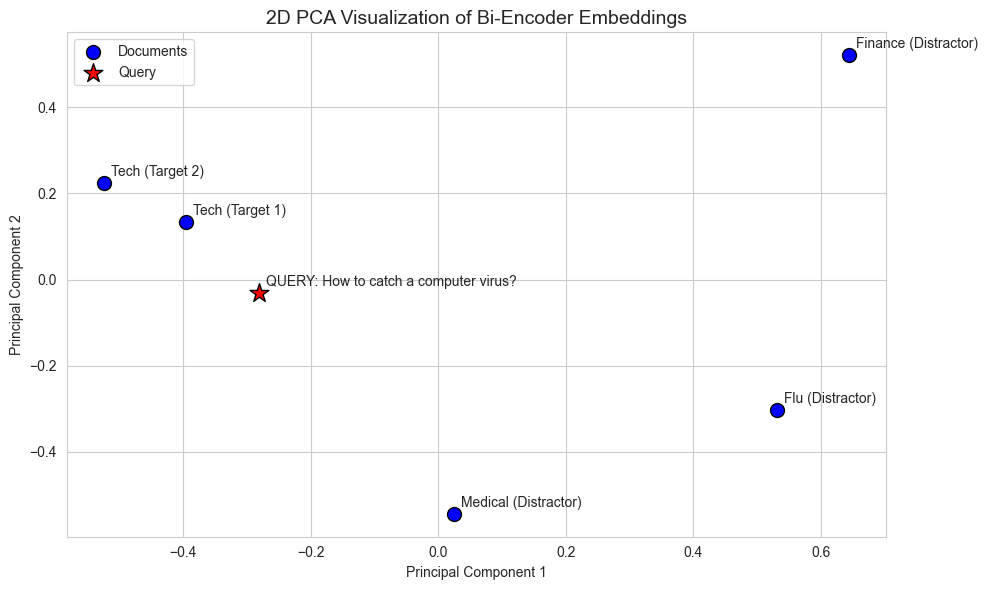

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA
from sentence_transformers import SentenceTransformer, CrossEncoder

# =====================================================================
# 1. SETUP: Load HuggingFace Models
# =====================================================================
print("Loading models... (This may take a moment on the first run)")

# Bi-Encoder: A popular, fast dense embedding model (calculates separately)
bi_encoder = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')

# Cross-Encoder: A standard neural ranker trained on MS MARCO (calculates together)
cross_encoder = CrossEncoder('cross-encoder/ms-marco-MiniLM-L-6-v2')

# =====================================================================
# 2. DATA PREPARATION: The "Virus" Polysemy Test
# =====================================================================
query = "How to catch a computer virus?"

# We include a mix of target documents and distractors to test the models
documents = [
    "To catch a virus early, doctors recommend regular screenings and washing hands.", # Distractor (Lexical overlap)
    "Downloading suspicious executable files is a common way to catch a computer virus.", # Target (Perfect match)
    "Protect your PC from malware, trojans, and phishing attacks using antivirus software.", # Target (Semantic, less lexical overlap)
    "The flu virus spreads rapidly during the winter months.", # Distractor
    "Apple stock caught a cold today as market shares plummeted." # Distractor
]

labels = ["Medical (Distractor)", "Tech (Target 1)", "Tech (Target 2)", "Flu (Distractor)", "Finance (Distractor)"]

print(f"\n--- QUERY ---\n'{query}'\n")

# =====================================================================
# 3. EXPERIMENT 1: Bi-Encoder (Calculating Separately)
# =====================================================================
print("--- EXPERIMENT 1: Bi-Encoder (Dense Passage Retrieval) ---")

# We embed the query and documents completely independently
query_embedding = bi_encoder.encode(query)       # Shape: (384,)
doc_embeddings = bi_encoder.encode(documents)    # Shape: (5, 384)

# Calculate Cosine Similarity (Dot product of normalized vectors)
# Reshape query for sklearn's similarity function
query_embedding_reshaped = query_embedding.reshape(1, -1) 
similarities = cosine_similarity(query_embedding_reshaped, doc_embeddings)[0]

print("Cosine Similarity Scores (Higher is better):")
for i, score in enumerate(similarities):
    print(f"[{score:.4f}] {labels[i]}: {documents[i][:50]}...")

# =====================================================================
# 4. EXPERIMENT 2: Cross-Encoder (Calculating Together)
# =====================================================================
print("\n--- EXPERIMENT 2: Cross-Encoder (Neural Reranker) ---")

# We format the input as a list of pairs: [[Query, Doc1], [Query, Doc2], ...]
cross_inp = [[query, doc] for doc in documents]

# The model reads them TOGETHER and outputs a relevance score
cross_scores = cross_encoder.predict(cross_inp)

print("Cross-Encoder Relevance Scores (Higher is better, scale varies):")
for i, score in enumerate(cross_scores):
    print(f"[{score:.4f}] {labels[i]}: {documents[i][:50]}...")

# =====================================================================
# 5. EXPERIMENT 3: Visualizing the Separated Embeddings
# =====================================================================
print("\n--- EXPERIMENT 3: Generating 2D Plot of Embeddings ---")

# Combine the query and documents into one array for PCA
all_embeddings = np.vstack([query_embedding, doc_embeddings])
all_texts = ["QUERY: " + query] + labels

# Use PCA to reduce the 384 dimensions down to 2 so we can graph it on an X/Y axis
pca = PCA(n_components=2)
reduced_embeddings = pca.fit_transform(all_embeddings)

# Extract X and Y coordinates
x = reduced_embeddings[:, 0]
y = reduced_embeddings[:, 1]

# Plotting
plt.figure(figsize=(10, 6))
sns.set_style("whitegrid")

# Plot documents
plt.scatter(x[1:], y[1:], c='blue', s=100, label='Documents', edgecolors='black')
# Plot query
plt.scatter(x[0], y[0], c='red', s=200, marker='*', label='Query', edgecolors='black')

# Annotate the points
for i, text in enumerate(all_texts):
    plt.annotate(text, (x[i], y[i]), xytext=(5, 5), textcoords='offset points', fontsize=10)

plt.title("2D PCA Visualization of Bi-Encoder Embeddings", fontsize=14)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.tight_layout()

print("Displaying plot... (Close the plot window to finish script)")
plt.show()